# MSH chain: tensor networks vs exact diagonalization

Compares the two implementations of the MSH chain, number by number:

| File | Written by | Method |
|---|---|---|
| `msh_chain_tn_results.npz` | `msh_chain_tn.ipynb` (Julia, TensorBinding) | MPO/MPS: KPM, DMRG, TDVP (plus the dense checks of that notebook) |
| `msh_compare_python.npz` | `msh_chain_python_ed.ipynb` (Python, NumPy) | dense BdG exact diagonalization and exact time evolution |

Run both notebooks first, in this directory. This notebook only loads the two files and compares them, so it runs in seconds.

Each row prints max |Julia − Python| against a tolerance:
- **Dense against dense** (spectra, Lorentzian LDOS, exact KPM, exact $\Delta Q$ and $\delta n$, exact ramp) should agree to round-off.
- **Tensor network against dense** (`get_ldos_spatial`, DMRG Majoranas, MPS $\Delta Q$, TDVP ramp) agrees to the truncation error of the method.
  Section 6 lists, row by row, the error source each of these tolerances is set against.

**Contents**
1. Spectrum and Lorentzian LDOS
2. KPM LDOS
3. Majorana modes
4. Charge difference vs segment length
5. Spin ramp
6. Summary

**Conventions.** The two notebooks use different Nambu bases, (c↑, c↓, c†↑, c†↓) in Julia and (c↑, c↓, c†↓, −c†↑) in Python, so only
basis-independent quantities are compared: spectra, spin-summed LDOS and densities, $\Delta Q$. The Python model has the opposite Rashba sign
($-t - i\alpha\sigma_y$ on $H_{i+1,i}$); static quantities do not depend on it, and the ramp rows use the Python run with $\alpha = -0.9$
(`ramp_julia_*`), which is the Julia model. Sites are 0-indexed in both files.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

tn = np.load("msh_chain_tn_results.npz")     # msh_chain_tn.ipynb
py = np.load("msh_compare_python.npz")       # msh_chain_python_ed.ipynb

rows = []   # (section, name, max |Julia − Python|, tolerance)
def check(section, name, a, b, tol):
    d = float(np.max(np.abs(np.asarray(a) - np.asarray(b))))
    rows.append((section, name, d, tol))
    print(f"{name:<58s} {d:9.1e}  (tol {tol:.0e})  {'✓' if d <= tol else '✗'}")

snap = ["t = 0", "t = T/3", "t = 2T/3", "t = T"]     # the four spin-ramp snapshots of the LDOS sections
L = 6; N = 2**L
sites = np.arange(N)

## 1. Spectrum and Lorentzian LDOS

Julia section 5 / Python section 2: $|E|_1$, $|E|_3$ of the uniform rotation $f = 0, 0.1, \dots, 1$.
Julia section 6 / Python section 3: particle and hole LDOS ($\eta = 0.03$) of the four snapshots of the spin ramp. Both sides are dense.

In [2]:
check("dense", "f sweep |E|₁, |E|₃", tn["sweep_E13"], py["sweep_E13"], 1e-9)
for j in range(4):
    check("dense", f"Lorentzian LDOS particle, hole: {snap[j]}",
          np.hstack([tn[f"ldos_p_{j}"], tn[f"ldos_h_{j}"]]), np.hstack([py[f"ldos_p_{j}"], py[f"ldos_h_{j}"]]), 1e-9)

f sweep |E|₁, |E|₃                                           2.8e-14  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = 0                        8.7e-13  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = T/3                      7.5e-12  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = 2T/3                     1.2e-11  (tol 1e-09)  ✓
Lorentzian LDOS particle, hole: t = T                        3.8e-12  (tol 1e-09)  ✓


## 2. KPM LDOS

Julia section 7a / Python section 4: particle + hole LDOS with the Jackson kernel, `Ncheb = 1024`. Julia has two versions: TensorBinding's
`get_ldos_spatial` on the MPO, and `kpm_exact`, the same Chebyshev formula applied to the exact eigenpairs. Python has the exact version.
The exact rows test the KPM formula and normalization (round-off); the `get_ldos_spatial` rows test the tensor-network arithmetic.

**Plot.** $\omega = 0$ cut of each snapshot: `get_ldos_spatial` (line), Julia `kpm_exact` (dashed) and Python (markers).

kpm_exact (Julia) vs Python, p+h: t = 0                      3.8e-13  (tol 1e-09)  ✓
kpm_exact (Julia) vs Python, p+h: t = T/3                    3.4e-12  (tol 1e-09)  ✓
kpm_exact (Julia) vs Python, p+h: t = 2T/3                   9.0e-12  (tol 1e-09)  ✓
kpm_exact (Julia) vs Python, p+h: t = T                      1.8e-12  (tol 1e-09)  ✓
get_ldos_spatial, Ncheb = 1024, p+h: t = 0                   5.3e-06  (tol 1e-04)  ✓
get_ldos_spatial, Ncheb = 1024, p+h: t = T/3                 3.8e-06  (tol 1e-04)  ✓
get_ldos_spatial, Ncheb = 1024, p+h: t = 2T/3                3.6e-06  (tol 1e-04)  ✓
get_ldos_spatial, Ncheb = 1024, p+h: t = T                   3.4e-05  (tol 1e-04)  ✓


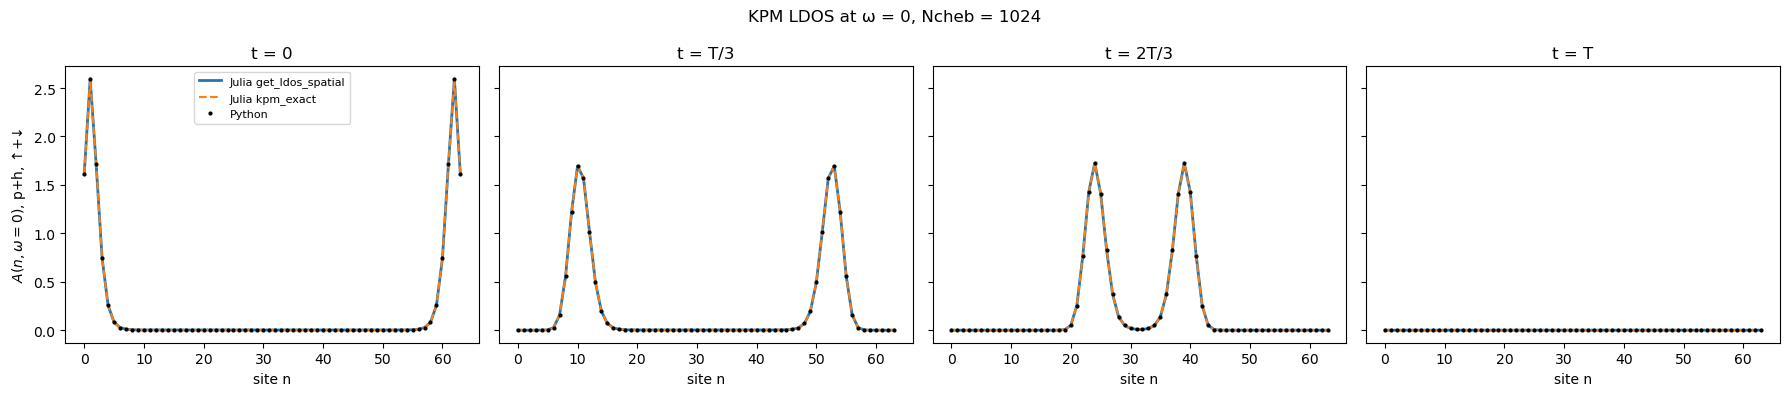

In [3]:
for j in range(4):
    check("dense", f"kpm_exact (Julia) vs Python, p+h: {snap[j]}", tn[f"kpm1024_exact_{j}"], py[f"kpm1024_ph_{j}"], 1e-9)
for j in range(4):
    check("tn", f"get_ldos_spatial, Ncheb = 1024, p+h: {snap[j]}", tn[f"kpm1024_tb_{j}"], py[f"kpm1024_ph_{j}"], 1e-4)

i0 = np.argmin(np.abs(py["kpm1024_omega"]))
fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for j in range(4):
    ax[j].plot(sites, tn[f"kpm1024_tb_{j}"][i0], lw=2, label="Julia get_ldos_spatial")
    ax[j].plot(sites, tn[f"kpm1024_exact_{j}"][i0], "--", lw=1.5, label="Julia kpm_exact")
    ax[j].plot(sites, py[f"kpm1024_ph_{j}"][i0], "k.", ms=4, label="Python")
    ax[j].set_title(snap[j]); ax[j].set_xlabel("site n")
ax[0].set_ylabel(r"$A(n, \omega = 0)$, p+h, ↑+↓"); ax[0].legend(fontsize=8)
fig.suptitle("KPM LDOS at ω = 0, Ncheb = 1024")
fig.tight_layout()
plt.show()

## 3. Majorana modes

Julia section 8a (DMRG on $H^2$, localization, $C\gamma = \gamma$) / Python section 5 (Takagi factorization of the exact zero-mode pair),
for all spins along $\hat z$ (Majoranas at the chain ends) and a topological middle half (Majoranas at the domain walls).

**Plot.** $|\gamma_i(n)|^2$ (p + h, ↑ + ↓) on a log scale: Python lines, Julia markers.

Majorana centers: f = 0                                      2.0e-09  (tol 1e-04)  ✓
|γ₁|², |γ₂|² profiles: f = 0                                 3.3e-10  (tol 1e-06)  ✓
E_f: f = 0                                                   2.0e-15  (tol 1e-09)  ✓
Majorana centers: domain                                     1.3e-08  (tol 1e-04)  ✓
|γ₁|², |γ₂|² profiles: domain                                3.7e-09  (tol 1e-06)  ✓
E_f: domain                                                  3.5e-15  (tol 1e-09)  ✓


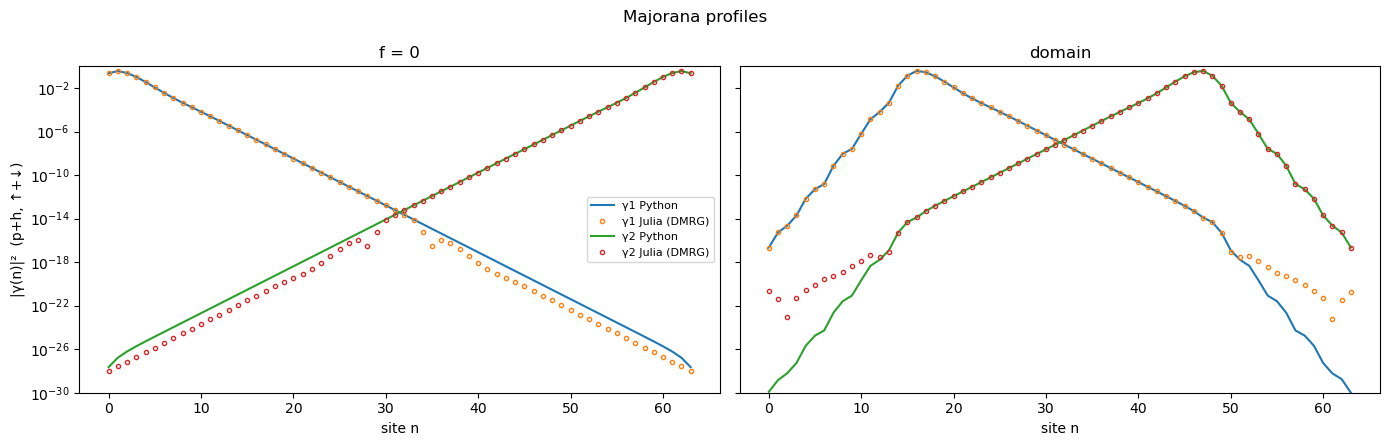

In [4]:
textures = ["f = 0", "domain"]
for j in range(2):
    check("tn", f"Majorana centers: {textures[j]}", tn[f"mzm_centers_{j}"], py[f"mzm_centers_{j}"], 1e-4)
    check("tn", f"|γ₁|², |γ₂|² profiles: {textures[j]}", tn[f"mzm_gamma_weight_{j}"], py[f"mzm_gamma_weight_{j}"], 1e-6)
    check("tn", f"E_f: {textures[j]}", tn[f"mzm_E_f_{j}"], py[f"mzm_E_f_{j}"], 1e-9)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for j in range(2):
    for i in range(2):
        ax[j].semilogy(sites, np.maximum(py[f"mzm_gamma_weight_{j}"][i], 1e-30), lw=1.5, label=f"γ{i+1} Python")
        ax[j].semilogy(sites, np.maximum(tn[f"mzm_gamma_weight_{j}"][i], 1e-30), "o", ms=3, mfc="none", label=f"γ{i+1} Julia (DMRG)")
    ax[j].set_ylim(1e-30, 1); ax[j].set_title(textures[j]); ax[j].set_xlabel("site n")
ax[0].set_ylabel("|γ(n)|²  (p+h, ↑+↓)"); ax[0].legend(fontsize=8)
fig.suptitle("Majorana profiles")
fig.tight_layout()
plt.show()

## 4. Charge difference vs segment length

Julia section 9a / Python section 6: a centered topological segment of $\ell$ sites, $\ell = 2, 4, \dots, 48$.
- The exact rows compare dense with dense: Julia's `exact_pair_charge` against Python's single-mode $\langle\psi_f|\tau_z|\psi_f\rangle$, the
  many-body $Q(|1\rangle) - Q(|0\rangle)$ from the masks, $-\partial E_f/\partial\mu$ (both finite differences with $d\mu = 10^{-4}$), $E_f$ and $\delta n(x)$.
- The MPS row compares Julia's DMRG value (with the inverse-iteration step where $E_f < 2\times10^{-6}$) with Python.

**Plot.** Left: $|\Delta Q|$ against $\ell$. Right: $|\Delta Q_{\rm Julia} - \Delta Q_{\rm Python}|$ on a log scale, for the MPS values with and without
refinement and for Julia's exact value.

exact ΔQ(ℓ): Julia vs Python single mode                     2.4e-14  (tol 1e-09)  ✓
exact ΔQ(ℓ): Julia vs Python many-body (masks)               2.7e-14  (tol 1e-09)  ✓
−∂E_f/∂μ (finite difference)                                 4.7e-11  (tol 1e-08)  ✓
E_f(ℓ)                                                       1.1e-14  (tol 1e-09)  ✓
exact δn(x) for every ℓ                                      7.1e-15  (tol 1e-09)  ✓
MPS ΔQ(ℓ)                                                    2.3e-08  (tol 1e-06)  ✓


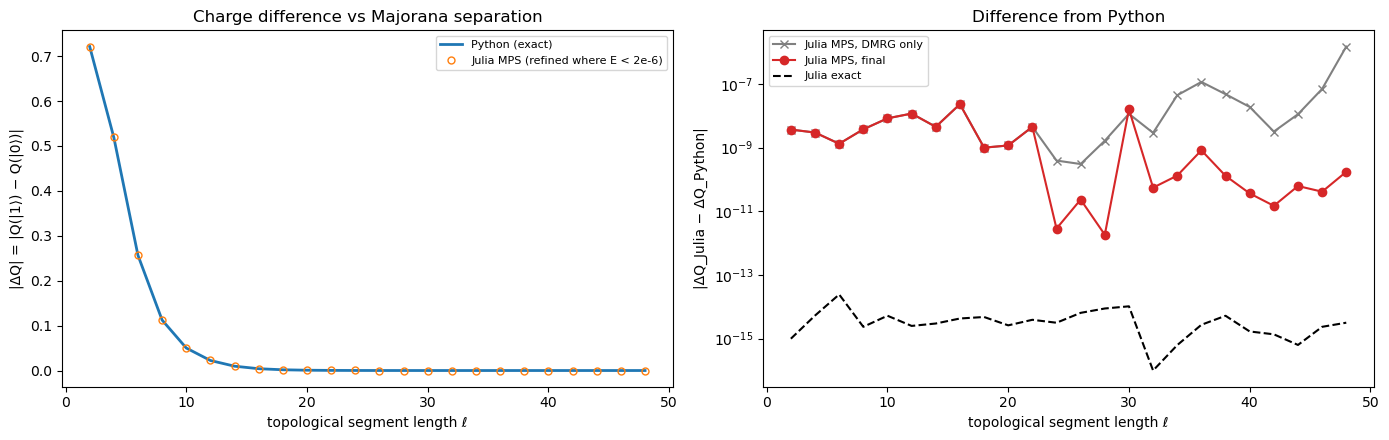

In [5]:
ells = py["charge_ells"]
assert np.array_equal(tn["charge_ells"], ells)
check("dense", "exact ΔQ(ℓ): Julia vs Python single mode", tn["charge_dQ_exact"], py["charge_dQ"], 1e-9)
check("dense", "exact ΔQ(ℓ): Julia vs Python many-body (masks)", tn["charge_dQ_exact"], py["charge_dQ_mb"], 1e-9)
check("dense", "−∂E_f/∂μ (finite difference)", tn["charge_dQ_FH"], py["charge_dQ_FH"], 1e-8)
check("dense", "E_f(ℓ)", tn["charge_E_exact"], py["charge_E"], 1e-9)
check("dense", "exact δn(x) for every ℓ", tn["charge_dn_exact"], py["charge_dn"], 1e-9)
check("tn", "MPS ΔQ(ℓ)", tn["charge_dQ_mps"], py["charge_dQ"], 1e-6)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ells, np.abs(py["charge_dQ"]), "-", lw=2, label="Python (exact)")
ax[0].plot(ells, np.abs(tn["charge_dQ_mps"]), "o", ms=5, mfc="none", label="Julia MPS (refined where E < 2e-6)")
ax[0].set_xlabel("topological segment length ℓ"); ax[0].set_ylabel("|ΔQ| = |Q(|1⟩) − Q(|0⟩)|")
ax[0].set_title("Charge difference vs Majorana separation"); ax[0].legend(fontsize=8)
err = lambda a: np.maximum(np.abs(a - py["charge_dQ"]), 1e-16)
ax[1].semilogy(ells, err(tn["charge_dQ_mps_raw"]), "x-", color="gray", label="Julia MPS, DMRG only")
ax[1].semilogy(ells, err(tn["charge_dQ_mps"]), "o-", color="tab:red", label="Julia MPS, final")
ax[1].semilogy(ells, err(tn["charge_dQ_exact"]), "--", color="k", label="Julia exact")
ax[1].set_xlabel("topological segment length ℓ"); ax[1].set_ylabel("|ΔQ_Julia − ΔQ_Python|")
ax[1].set_title("Difference from Python"); ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Spin ramp

Julia section 10a / Python section 7: the two-sided spin ramp with `rot_T = 100`, `step_T = 0.1`, $\ell_{\rm final} = 4$ ($T = 390$), $\alpha = -0.9$ in
Python's convention. Julia evolves $\psi_f$ by TDVP and, as a reference, by the dense midpoint propagator; Python evolves the full BdG unitary
with the same propagator and takes $\delta n$, $\Delta Q$ from the masks. Both sample the same 201 times.

**Plot.** Left: $\Delta Q(t)$ from TDVP, Julia's exact evolution and Python, with Julia's instantaneous adiabatic value. Right: the differences from
Python on a log scale.

exact ΔQ(t)                                                  3.7e-14  (tol 1e-09)  ✓
exact δn(x, t)                                               2.0e-14  (tol 1e-09)  ✓
exact leakage                                                1.0e-14  (tol 1e-09)  ✓
adiabatic ΔQ at t = T                                        1.3e-14  (tol 1e-09)  ✓
MPS / TDVP ΔQ(t)                                             4.1e-07  (tol 1e-04)  ✓
MPS / TDVP δn(x, t)                                          2.6e-07  (tol 1e-04)  ✓
MPS / TDVP leakage                                           2.9e-09  (tol 1e-06)  ✓


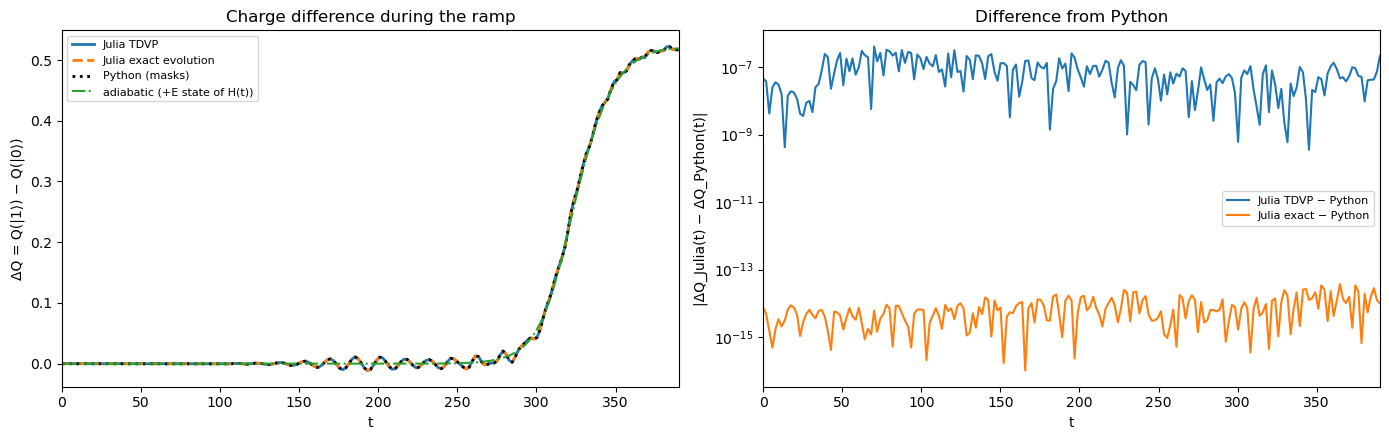

In [6]:
ts = py["ramp_julia_times"]
assert np.allclose(tn["ramp_times"], ts)
check("dense", "exact ΔQ(t)", tn["ramp_dQ_t_exact"], py["ramp_julia_dQ_t"], 1e-9)
check("dense", "exact δn(x, t)", tn["ramp_dn_t_exact"], py["ramp_julia_dn_t"], 1e-9)
check("dense", "exact leakage", tn["ramp_leak_exact"], py["ramp_julia_leak"], 1e-9)
check("dense", "adiabatic ΔQ at t = T", tn["ramp_dQ_adiabatic_t"][-1], py["ramp_julia_dQ_adiabatic"], 1e-9)
check("tn", "MPS / TDVP ΔQ(t)", tn["ramp_dQ_t_mps"], py["ramp_julia_dQ_t"], 1e-4)
check("tn", "MPS / TDVP δn(x, t)", tn["ramp_dn_t_mps"], py["ramp_julia_dn_t"], 1e-4)
check("tn", "MPS / TDVP leakage", tn["ramp_leak_mps"], py["ramp_julia_leak"], 1e-6)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ts, tn["ramp_dQ_t_mps"], lw=2, label="Julia TDVP")
ax[0].plot(ts, tn["ramp_dQ_t_exact"], "--", lw=2, label="Julia exact evolution")
ax[0].plot(ts, py["ramp_julia_dQ_t"], "k:", lw=2, label="Python (masks)")
ax[0].plot(ts, tn["ramp_dQ_adiabatic_t"], "-.", lw=1.5, label="adiabatic (+E state of H(t))")
ax[0].set_xlim(ts[0], ts[-1]); ax[0].set_xlabel("t"); ax[0].set_ylabel("ΔQ = Q(|1⟩) − Q(|0⟩)")
ax[0].set_title("Charge difference during the ramp"); ax[0].legend(fontsize=8)
ax[1].semilogy(ts, np.maximum(np.abs(tn["ramp_dQ_t_mps"] - py["ramp_julia_dQ_t"]), 1e-17), label="Julia TDVP − Python")
ax[1].semilogy(ts, np.maximum(np.abs(tn["ramp_dQ_t_exact"] - py["ramp_julia_dQ_t"]), 1e-17), label="Julia exact − Python")
ax[1].set_xlim(ts[0], ts[-1]); ax[1].set_xlabel("t"); ax[1].set_ylabel("|ΔQ_Julia(t) − ΔQ_Python(t)|")
ax[1].set_title("Difference from Python"); ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6. Summary

Every row, with its difference and tolerance. Dense-against-dense rows are blue, tensor-network rows orange.

**Tensor-network tolerances, row by row.** Dense rows use $10^{-9}$ (round-off, with room for the conditioning of each quantity) and
$10^{-8}$ for the finite difference $-\partial E_f/\partial\mu$ ($d\mu = 10^{-4}$). Each tensor-network tolerance is set by the error source of
that method, at the size it would have in an unconverged but still acceptable run, not by the (much smaller) error of this run:

| Row | Tolerance | Error source and scale | This run |
|---|---|---|---|
| `get_ldos_spatial`, 4 snapshots | $10^{-4}$ | The MPO Chebyshev recursion is truncated at each of the 1024 steps (`maxdim = 512`, `cutoff = 1e-12`); the error accumulates over the recursion and grows with the entanglement of $H$ (largest at $t = T$). $10^{-4}$ is about $2\times10^{-5}$ of the LDOS peak ($\approx 4.9$). | $3.4\times10^{-6}$ – $3.4\times10^{-5}$ |
| Majorana centres | $10^{-4}$ (sites) | $\langle x\rangle$ is linear in the DMRG weight error $\varepsilon$ with lever arm up to $N = 64$ sites; $10^{-4}$ of a site corresponds to $\varepsilon \sim 10^{-6}$. | $2\times10^{-9}$, $1.3\times10^{-8}$ |
| $\lvert\gamma\rvert^2$ profiles | $10^{-6}$ | DMRG on $K = H^2 + \eta^2$ leaves a bulk admixture of amplitude $10^{-7}$–$10^{-6}$ (Julia section 8); the profiles are weights, so their error is of that order at most. | $3\times10^{-10}$, $4\times10^{-9}$ |
| $E_f$ | $10^{-9}$ | Energy is quadratic in the state error, so even a $10^{-6}$ amplitude error gives $\lesssim 10^{-12}$ in $E_f$; the tolerance is the dense one. | $2\times10^{-15}$, $3.5\times10^{-15}$ |
| MPS $\Delta Q(\ell)$ | $10^{-6}$ | $\Delta Q$ is linear in the bulk admixture. Without the refinement step the DMRG values are off by up to $1.5\times10^{-6}$ (the gray curve of section 4); the tolerance asks for the refined accuracy. | $2.3\times10^{-8}$ |
| TDVP $\Delta Q(t)$, $\delta n(x,t)$ | $10^{-4}$ | Both sides use the same midpoint propagator, so the time-step error cancels. What remains is the TDVP projection and Krylov error ($\text{tol} = 10^{-12}$ per step, 3900 steps, `maxdim = 64`) and the DMRG error of $\psi_f(0)$, against $|\Delta Q| \le 0.52$ and $|\delta n| \le 0.15$. | $4.1\times10^{-7}$, $2.6\times10^{-7}$ |
| TDVP leakage | $10^{-6}$ | The leakage itself is $2.1\times10^{-4}$; $10^{-6}$ asks for it to better than 0.5 %. | $2.9\times10^{-9}$ |

The summary prints, for each class, the row closest to its tolerance.

32 of 32 comparisons within tolerance
dense rows: closest to tolerance is 'Lorentzian LDOS particle, hole: t = 2T/3', 1.2e-11 = 1.2e-02 × tol
tensor-network rows: closest to tolerance is 'get_ldos_spatial, Ncheb = 1024, p+h: t = T', 3.4e-05 = 3.4e-01 × tol


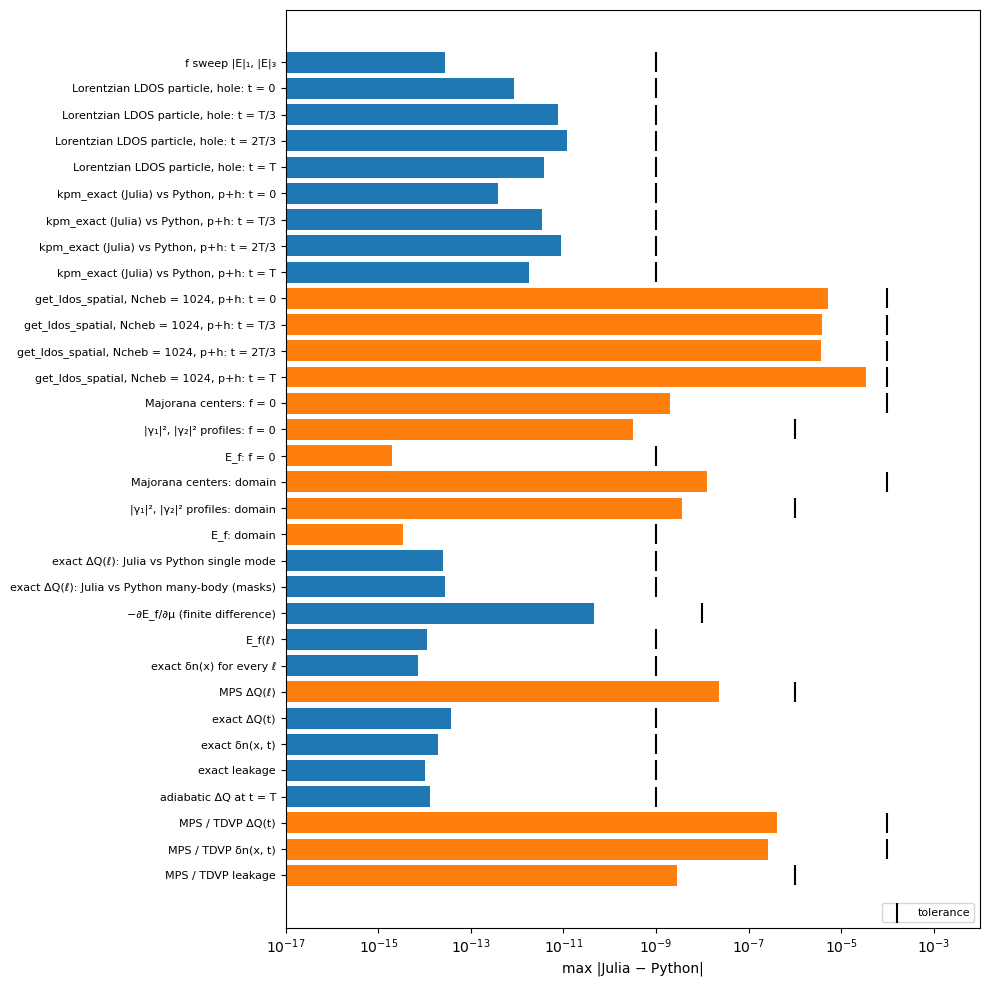

In [7]:
ok = sum(d <= tol for _, _, d, tol in rows)
print(f"{ok} of {len(rows)} comparisons within tolerance")
for sec, name, d, tol in rows:
    if d > tol:
        print(f"  ✗ {name}: {d:.1e} > {tol:.0e}")
for cls, label in (("dense", "dense rows"), ("tn", "tensor-network rows")):
    sec, name, d, tol = max((r for r in rows if r[0] == cls), key=lambda r: r[2] / r[3])
    print(f"{label}: closest to tolerance is '{name.strip()}', {d:.1e} = {d / tol:.1e} × tol")

fig, ax = plt.subplots(figsize=(10, 0.28 * len(rows) + 1))
y = np.arange(len(rows))[::-1]
ax.barh(y, [max(d, 1e-17) for _, _, d, _ in rows], color=["tab:blue" if s == "dense" else "tab:orange" for s, *_ in rows])
ax.scatter([tol for *_, tol in rows], y, marker="|", s=200, color="k", label="tolerance")
ax.set_xscale("log"); ax.set_xlim(1e-17, 1e-2)
ax.set_yticks(y); ax.set_yticklabels([name for _, name, _, _ in rows], fontsize=8)
ax.set_xlabel("max |Julia − Python|"); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()